# Oráculo · Exploración descriptiva de mercados de volumen

Base extensible del Issue **[Feature] Implementar exploración descriptiva y definir
estrategia de mercado**. Fuente única: `database/oraculo.db`, en modo de solo lectura.
Ejecutar todas las celdas en orden, con el entorno virtual del proyecto, desde la raíz
o desde `ml_models/`. Las funciones reutilizables viven en `analisis_volumen.py`.

**Unidad de análisis:** equipo–partido–período y total partido–período. `ALL`, `1ST`
y `2ST` se estudian por separado; nunca se suman entre sí. Los NULL no son ceros.
Las correlaciones contemporáneas describen el pasado y no son features pre-partido.
Este EDA no demuestra rentabilidad ni autoriza operación real.

## Sección 1 · Configuración y Auditoría de Cobertura

Se valida el contrato de columnas, `quick_check`, claves foráneas, unicidad estadística,
los tres períodos y exactamente un local y un visitante por partido. Una anomalía
estructural detiene el análisis para evitar multiplicaciones silenciosas en los JOIN.
La conexión usa URI `mode=ro`, `query_only` y una instantánea transaccional; se cierra
al terminar la extracción, incluso ante errores.

In [1]:
from pathlib import Path
import sys
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

# Bootstrap portable del módulo, sin rutas absolutas ni dependencia del cwd del kernel.
inicio = Path.cwd().resolve()
RAIZ = next((p for p in (inicio, *inicio.parents)
             if (p / "database").is_dir() and (p / "ml_models").is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError("Ejecutar desde la raíz del proyecto o ml_models/.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from ml_models.analisis_volumen import (
    PERIODOS, MERCADOS, METRICAS, CONTEOS, SQL_EQUIPO_PERIODO, SQL_TOTALES,
    conectar_solo_lectura, auditar, limpiar_equipo, construir_totales,
    describir, ranking_estabilidad, detectar_atipicos, ajustar_conteos,
    tabla_ajustes, correlaciones,
)

# Umbrales exploratorios: ajustar solo con entrenamiento en la futura Fase 2.
MIN_N_ESTABILIDAD = 30
MIN_COBERTURA_PCT = 90
MIN_N_CORRELACION = 30
MIN_N_IQR = 8
PERIODO_GRAFICO = "ALL"

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 22)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
display(pd.Series({"Python": platform.python_version(), **{
    p: version(p) for p in ("pandas", "numpy", "scipy", "matplotlib", "seaborn")
}}, name="Versiones"))
display(Markdown(f"**Ejecución UTC:** {pd.Timestamp.now(tz='UTC').isoformat()}"))

Python        3.13.2
pandas         3.0.5
numpy          2.5.1
scipy         1.18.1
matplotlib    3.11.2
seaborn       0.13.2
Name: Versiones, dtype: str

**Ejecución UTC:** 2026-11-23T21:31:33.903561+00:00

In [2]:
with conectar_solo_lectura(RAIZ) as conexion:
    auditoria = auditar(conexion)
    df_base_sql = pd.read_sql_query(SQL_EQUIPO_PERIODO, conexion)
    df_totales_sql = pd.read_sql_query(SQL_TOTALES, conexion)

display(Markdown("### Inventario e integridad"))
display(auditoria["resumen"], auditoria["integridad"])
display(Markdown(f"Incidencias de claves foráneas: {len(auditoria['claves_foraneas'])}."))
display(auditoria["cobertura"])
display(Markdown("### Porcentaje de NULL sobre filas estadísticas existentes"))
display(auditoria["nulos_sql_pct"])
if df_base_sql.empty:
    raise ValueError("La base no tiene observaciones: completar la carga ETL antes del EDA.")

### Inventario e integridad

,Paises,Ediciones_liga,Ligas,Temporadas,Rondas_liga_temporada,Partidos,Filas_estadisticas
0,80,3,1,3,87,869,5214


,quick_check
0,ok


Incidencias de claves foráneas: 0.

,Id_liga,Nombre_liga,Temporada,Partidos,Rondas,Desde_utc,Hasta_utc
0,61627,Premier League,24/25,380,38,2024-08-16T19:00:00Z,2025-05-25T15:00:00Z
1,76986,Premier League,25/26,380,38,2025-08-15T19:00:00Z,2026-05-24T15:00:00Z
2,96668,Premier League,26/27,109,11,2026-08-21T19:00:00Z,2026-11-22T16:30:00Z


### Porcentaje de NULL sobre filas estadísticas existentes

,Periodo,N_filas,Corners,Faltas,Saques_de_banda,Remates,Tiros_arco,Tiros_bloqueados,Tarjetas_amarillas,Tarjetas_rojas,Tiros_libres,Fueras_de_juego,Saques_de_arco,Total_centros,Entradas,Total_entradas,Posesion_balon,Goles_esperados_xG
0,1ST,1738,0.000,50.863,0.000,0.000,0.000,0.230,3.797,87.802,0.000,5.178,0.000,0.000,0.000,0.000,0.000,0.000
1,2ND,1738,0.000,50.863,0.000,0.000,0.000,0.230,3.797,87.802,0.000,5.178,0.000,0.000,0.000,0.000,0.000,0.000
2,ALL,1738,0.000,0.000,0.000,0.000,0.000,0.230,3.797,87.802,0.000,5.178,0.000,0.000,0.000,0.000,0.000,0.000


`LIGAS` identifica **ediciones** (liga–temporada). Se cuentan competiciones por
`Id_pais + Nombre_liga`, temporadas por etiqueta y rondas por `Id_liga + Ronda`,
sin mezclar la ronda 1 de dos ediciones. La cobertura es respecto de los partidos
cargados; no equivale a cobertura de la temporada completa ni del calendario oficial.
Los porcentajes siguientes incluyen períodos esperados sin fila estadística.

**Diferencia observada en la fuente:** SQLite contiene `2ND` para la segunda mitad.
La consulta normaliza únicamente esa etiqueta a `2ST` y conserva `Periodo_origen`.
La auditoría de NULL anterior muestra las etiquetas originales. Si coexistieran
`2ND` y `2ST` para un mismo equipo y partido, la auditoría detendría el JOIN por
duplicidad. No se modifica la base ni se reconstruyen mitades a partir de `ALL`.

In [3]:
df_equipo, incidencias_metricas = limpiar_equipo(df_base_sql)
cobertura_periodos = df_equipo.groupby("Periodo").agg(
    Filas_esperadas=("Id_partido", "size"),
    Filas_presentes=("Tiene_estadisticas", "sum"),
    Partidos=("Id_partido", "nunique"),
).reindex(PERIODOS)
cobertura_periodos["Filas_ausentes_pct"] = 100 * (
    1 - cobertura_periodos.Filas_presentes / cobertura_periodos.Filas_esperadas
)
nulos_limpios_pct = df_equipo.groupby("Periodo")[list(METRICAS)].agg(
    lambda s: 100 * s.isna().mean()
).reindex(PERIODOS)
display(cobertura_periodos, nulos_limpios_pct)
display(Markdown(f"**Valores inválidos convertidos a ausentes:** {len(incidencias_metricas)}. "
                 f"**Partidos con fecha inválida:** "
                 f"{df_equipo.loc[df_equipo.Fecha_hora_utc.isna(), 'Id_partido'].nunique()}."))
display(incidencias_metricas.head(20))

,Filas_esperadas,Filas_presentes,Partidos,Filas_ausentes_pct
Periodo,,,,
ALL,1738,1738,869,0.000
1ST,1738,1738,869,0.000
2ST,1738,1738,869,0.000


,Corners,Faltas,Saques_de_banda,Remates,Tiros_arco,Tiros_bloqueados,Tarjetas_amarillas,Tarjetas_rojas,Tiros_libres,Fueras_de_juego,Saques_de_arco,Total_centros,Entradas,Total_entradas,Posesion_balon,Goles_esperados_xG
Periodo,,,,,,,,,,,,,,,,
ALL,0.000,0.000,0.000,0.000,0.000,0.230,3.797,87.802,0.000,5.178,0.000,0.000,0.000,0.000,0.000,0.000
1ST,0.000,50.863,0.000,0.000,0.000,0.230,3.797,87.802,0.000,5.178,0.000,0.000,0.000,0.000,0.000,0.000
2ST,0.000,50.863,0.000,0.000,0.000,0.230,3.797,87.802,0.000,5.178,0.000,0.000,0.000,0.000,0.000,0.000


**Valores inválidos convertidos a ausentes:** 0. **Partidos con fecha inválida:** 0.

,Id_partido,Id_equipo,Periodo,Metrica,Valor_original


## Sección 2 · Capa de Datos Base (DataFrames limpios)

`SQL_EQUIPO_PERIODO` une estadísticas, participantes, partidos, equipos y ligas.
La cuadrícula de participantes × períodos conserva faltantes como `NaN`, con
`Tiene_estadisticas=0`. Conteos negativos, fraccionarios o no numéricos se marcan;
posesión debe estar entre 0 y 100 y xG ser no negativo. No se imputan observaciones.

`df_partido_total` suma local + visitante solo cuando **ambos** tienen la métrica
válida. Se suman conteos y xG; no se suma posesión. `SQL_TOTALES` expone también
el cálculo SQL sobre datos originales para contrastarlo con la capa limpia.

In [4]:
df_partido_total = construir_totales(df_equipo)
assert not df_equipo.duplicated(["Id_partido", "Id_equipo", "Periodo"]).any()
assert not df_partido_total.duplicated(["Id_partido", "Periodo"]).any()
assert df_partido_total.N_equipos.eq(2).all()

# Si no hubo saneamiento, las sumas SQL y pandas deben coincidir exactamente.
if incidencias_metricas.empty:
    claves = ["Id_partido", "Periodo"]
    pd.testing.assert_frame_equal(
        df_totales_sql.set_index(claves)[list(CONTEOS)].sort_index(),
        df_partido_total.set_index(claves)[list(CONTEOS)].sort_index(),
        check_dtype=False,
    )
display(df_equipo.head(6), df_partido_total.head(6))
display(describir(df_partido_total, ["Periodo"])[
    ["Periodo", "Mercado", "N", "N_esperado", "Cobertura_pct"]
])

# Control diagnóstico: ALL no se reconstruye desde las mitades. Diferencias pueden
# reflejar correcciones de la fuente, cobertura o semántica y requieren revisión.
revision_periodos = []
for mercado in MERCADOS:
    ancho = df_partido_total.pivot(index="Id_partido", columns="Periodo", values=mercado)
    completos = ancho.reindex(columns=PERIODOS).dropna()
    diferencia = completos["ALL"] - completos["1ST"] - completos["2ST"]
    revision_periodos.append({"Mercado": mercado, "Partidos_comparables": len(completos),
                              "ALL_distinto_suma_mitades": int(diferencia.ne(0).sum())})
display(pd.DataFrame(revision_periodos))

,Id_partido,Id_liga,Id_pais,Nombre_liga,Temporada,Ronda,Fecha_hora_utc,Goles_local,Goles_visita,Id_equipo,Nombre_equipo,...,Tarjetas_amarillas,Tarjetas_rojas,Tiros_libres,Fueras_de_juego,Saques_de_arco,Total_centros,Entradas,Total_entradas,Posesion_balon,Goles_esperados_xG,Condicion
0,12436870,61627,1,Premier League,24/25,1,2024-08-16 19:00:00+00:00,1,0,35,Manchester United,...,2.000,NaN,6.000,3.000,3.000,6.000,8.000,8.000,0.610,1.120,Local
1,12436870,61627,1,Premier League,24/25,1,2024-08-16 19:00:00+00:00,1,0,35,Manchester United,...,0.000,NaN,4.000,0.000,3.000,12.000,13.000,13.000,0.480,1.310,Local
2,12436870,61627,1,Premier League,24/25,1,2024-08-16 19:00:00+00:00,1,0,35,Manchester United,...,2.000,NaN,10.000,3.000,6.000,18.000,21.000,21.000,0.550,2.430,Local
3,12436870,61627,1,Premier League,24/25,1,2024-08-16 19:00:00+00:00,1,0,43,Fulham,...,1.000,NaN,5.000,1.000,6.000,4.000,10.000,10.000,0.390,0.100,Visita
4,12436870,61627,1,Premier League,24/25,1,2024-08-16 19:00:00+00:00,1,0,43,Fulham,...,2.000,NaN,6.000,0.000,4.000,17.000,14.000,14.000,0.520,0.340,Visita
5,12436870,61627,1,Premier League,24/25,1,2024-08-16 19:00:00+00:00,1,0,43,Fulham,...,3.000,NaN,11.000,1.000,10.000,21.000,24.000,24.000,0.450,0.440,Visita


,Id_partido,Periodo,Id_liga,Id_pais,Nombre_liga,Temporada,Ronda,Fecha_hora_utc,Corners,Faltas,Saques_de_banda,...,Tiros_bloqueados,Tarjetas_amarillas,Tarjetas_rojas,Tiros_libres,Fueras_de_juego,Saques_de_arco,Total_centros,Entradas,Total_entradas,Goles_esperados_xG,N_equipos
0,12436410,1ST,61627,1,Premier League,24/25,19,2025-01-01 17:30:00+00:00,3.000,NaN,6.000,...,6.000,2.000,NaN,6.000,3.000,9.000,19.000,14.000,14.000,1.080,2
1,12436410,2ST,61627,1,Premier League,24/25,19,2025-01-01 17:30:00+00:00,4.000,NaN,12.000,...,0.000,1.000,NaN,8.000,3.000,5.000,16.000,12.000,12.000,1.150,2
2,12436410,ALL,61627,1,Premier League,24/25,19,2025-01-01 17:30:00+00:00,7.000,14.000,18.000,...,6.000,3.000,NaN,14.000,6.000,14.000,35.000,26.000,26.000,2.230,2
3,12436419,1ST,61627,1,Premier League,24/25,20,2025-01-04 15:00:00+00:00,6.000,NaN,14.000,...,3.000,0.000,NaN,7.000,2.000,8.000,19.000,13.000,13.000,0.980,2
4,12436419,2ST,61627,1,Premier League,24/25,20,2025-01-04 15:00:00+00:00,6.000,NaN,19.000,...,6.000,2.000,NaN,14.000,0.000,6.000,14.000,25.000,25.000,1.340,2
5,12436419,ALL,61627,1,Premier League,24/25,20,2025-01-04 15:00:00+00:00,12.000,21.000,33.000,...,9.000,2.000,NaN,21.000,2.000,14.000,33.000,38.000,38.000,2.320,2


,Periodo,Mercado,N,N_esperado,Cobertura_pct
0,1ST,Corners,869,869,100.000
1,1ST,Faltas,427,869,49.137
2,1ST,Remates,869,869,100.000
3,1ST,Saques_de_banda,869,869,100.000
4,2ST,Corners,869,869,100.000
5,2ST,Faltas,427,869,49.137
6,2ST,Remates,869,869,100.000
7,2ST,Saques_de_banda,869,869,100.000
8,ALL,Corners,869,869,100.000
9,ALL,Faltas,869,869,100.000


,Mercado,Partidos_comparables,ALL_distinto_suma_mitades
0,Corners,869,0
1,Faltas,427,0
2,Saques_de_banda,869,0
3,Remates,869,0


## Sección 3 · Estadística Descriptiva por Mercado y Período

Media, desviación estándar muestral (`ddof=1`), mediana, cuartiles, IQR, CV y
asimetría muestral ajustada. CV se expresa como razón (0,30 = 30 %); es indefinido
si la media es cero o no hay dos observaciones. Asimetría necesita al menos tres.
`N` y cobertura acompañan todas las comparaciones. Las filas de los dos equipos
de un partido no son muestras independientes para inferencia.

In [5]:
descriptivos_equipo = describir(df_equipo, ["Periodo"])
descriptivos_total = describir(df_partido_total, ["Periodo"])
display(Markdown("### Equipo–partido–período"), descriptivos_equipo)
display(Markdown("### Total partido–período"), descriptivos_total)

### Equipo–partido–período

,Periodo,Mercado,N,N_esperado,Media,DE,Mediana,Q25,Q75,Asimetria,IQR,CV,Cobertura_pct
0,1ST,Corners,1738,1738,2.369,1.830,2.000,1.000,3.000,0.928,2.000,0.772,100.000
1,1ST,Faltas,854,1738,5.315,2.215,5.000,4.000,7.000,0.162,3.000,0.417,49.137
2,1ST,Remates,1738,1738,5.881,3.096,5.000,4.000,8.000,0.670,4.000,0.526,100.000
3,1ST,Saques_de_banda,1738,1738,8.484,3.351,8.000,6.000,11.000,0.510,5.000,0.395,100.000
4,2ST,Corners,1738,1738,2.650,2.016,2.000,1.000,4.000,1.074,3.000,0.761,100.000
5,2ST,Faltas,854,1738,5.678,2.499,5.000,4.000,7.000,0.427,3.000,0.440,49.137
6,2ST,Remates,1738,1738,6.976,3.615,7.000,4.000,9.000,0.872,5.000,0.518,100.000
7,2ST,Saques_de_banda,1738,1738,8.725,3.424,8.000,6.000,11.000,0.486,5.000,0.392,100.000
8,ALL,Corners,1738,1738,5.020,2.900,5.000,3.000,7.000,0.805,4.000,0.578,100.000
9,ALL,Faltas,1738,1738,11.037,3.554,11.000,9.000,13.000,0.241,4.000,0.322,100.000


### Total partido–período

,Periodo,Mercado,N,N_esperado,Media,DE,Mediana,Q25,Q75,Asimetria,IQR,CV,Cobertura_pct
0,1ST,Corners,869,869,4.739,2.331,5.000,3.000,6.000,0.527,3.000,0.492,100.000
1,1ST,Faltas,427,869,10.630,3.041,10.000,9.000,13.000,0.273,4.000,0.286,49.137
2,1ST,Remates,869,869,11.763,3.603,12.000,9.000,14.000,0.384,5.000,0.306,100.000
3,1ST,Saques_de_banda,869,869,16.969,4.913,17.000,13.000,20.000,0.401,7.000,0.290,100.000
4,2ST,Corners,869,869,5.300,2.402,5.000,4.000,7.000,0.573,3.000,0.453,100.000
5,2ST,Faltas,427,869,11.356,3.538,11.000,9.000,14.000,0.221,5.000,0.312,49.137
6,2ST,Remates,869,869,13.952,4.148,14.000,11.000,17.000,0.389,6.000,0.297,100.000
7,2ST,Saques_de_banda,869,869,17.450,4.885,17.000,14.000,21.000,0.242,7.000,0.280,100.000
8,ALL,Corners,869,869,10.039,3.354,10.000,8.000,12.000,0.216,4.000,0.334,100.000
9,ALL,Faltas,869,869,22.074,5.156,22.000,18.000,26.000,0.214,8.000,0.234,100.000


## Sección 4 · Local vs. Visitante y Estabilidad por Liga/Equipo

Comparación por condición y diferencia **pareada** local − visita en el mismo
encuentro. Rankings separados por período y mercado: ligas sobre totales por
edición; equipos sobre sus propios conteos por edición. Exigimos `N >= 30` y
cobertura >= 90 %; los demás grupos permanecen visibles con `Elegible=False`.
Un CV bajo no implica que una línea tenga valor ni que el patrón persista.

In [6]:
comparativa_local_visita = describir(df_equipo, ["Periodo", "Condicion"])
pares = df_equipo.pivot(index=["Id_partido", "Periodo"], columns="Condicion", values=list(MERCADOS))
diferencias = pd.DataFrame({
    mercado: pares[(mercado, "Local")] - pares[(mercado, "Visita")]
    for mercado in MERCADOS
}).reset_index()
# No interpretamos CV de diferencias (su media puede ser cero o negativa).
comparativa_pareada = describir(diferencias, ["Periodo"]).drop(columns="CV")
ranking_ligas = ranking_estabilidad(
    df_partido_total, ["Id_liga", "Nombre_liga", "Temporada", "Periodo"],
    MIN_N_ESTABILIDAD, MIN_COBERTURA_PCT,
)
ranking_equipos = ranking_estabilidad(
    df_equipo, ["Id_liga", "Nombre_liga", "Temporada", "Id_equipo", "Nombre_equipo", "Periodo"],
    MIN_N_ESTABILIDAD, MIN_COBERTURA_PCT,
)
display(comparativa_local_visita, comparativa_pareada)
display(Markdown("### Ligas: comparación dentro del mismo mercado y período"), ranking_ligas)
display(Markdown("### Equipos elegibles (hasta 3 por mercado y período)"))
display(ranking_equipos.loc[ranking_equipos.Elegible].groupby(
    ["Periodo", "Mercado"], group_keys=False).head(3))
display(Markdown(f"Grupos equipo–edición–período–mercado evaluados: {len(ranking_equipos)}; "
                 f"elegibles: {int(ranking_equipos.Elegible.sum())}."))
display(ranking_equipos.loc[~ranking_equipos.Elegible].head(12))

,Periodo,Condicion,Mercado,N,N_esperado,Media,DE,Mediana,Q25,Q75,Asimetria,IQR,CV,Cobertura_pct
0,1ST,Local,Corners,869,869,2.527,1.861,2.000,1.000,4.000,0.913,3.000,0.736,100.000
1,1ST,Local,Faltas,427,869,5.185,2.108,5.000,4.000,7.000,0.244,3.000,0.406,49.137
2,1ST,Local,Remates,869,869,6.371,3.088,6.000,4.000,8.000,0.520,4.000,0.485,100.000
3,1ST,Local,Saques_de_banda,869,869,8.672,3.423,8.000,6.000,11.000,0.478,5.000,0.395,100.000
4,1ST,Visita,Corners,869,869,2.212,1.785,2.000,1.000,3.000,0.945,2.000,0.807,100.000
5,1ST,Visita,Faltas,427,869,5.445,2.313,5.000,4.000,7.000,0.072,3.000,0.425,49.137
6,1ST,Visita,Remates,869,869,5.392,3.028,5.000,3.000,7.000,0.864,4.000,0.561,100.000
7,1ST,Visita,Saques_de_banda,869,869,8.297,3.270,8.000,6.000,10.000,0.535,4.000,0.394,100.000
8,2ST,Local,Corners,869,869,2.826,2.108,2.000,1.000,4.000,0.988,3.000,0.746,100.000
9,2ST,Local,Faltas,427,869,5.646,2.519,5.000,4.000,7.000,0.551,3.000,0.446,49.137


,Periodo,Mercado,N,N_esperado,Media,DE,Mediana,Q25,Q75,Asimetria,IQR,Cobertura_pct
0,1ST,Corners,869,869,0.315,2.805,0.000,-1.000,2.000,-0.035,3.000,100.000
1,1ST,Faltas,427,869,-0.260,3.215,0.000,-3.000,2.000,0.102,5.000,49.137
2,1ST,Remates,869,869,0.978,4.942,1.000,-2.000,4.000,-0.140,6.000,100.000
3,1ST,Saques_de_banda,869,869,0.375,4.547,0.000,-3.000,3.000,0.032,6.000,100.000
4,2ST,Corners,869,869,0.352,3.220,0.000,-2.000,3.000,0.056,5.000,100.000
5,2ST,Faltas,427,869,-0.063,3.535,0.000,-2.000,2.000,0.191,4.000,49.137
6,2ST,Remates,869,869,1.162,5.809,1.000,-2.000,5.000,-0.015,7.000,100.000
7,2ST,Saques_de_banda,869,869,0.442,4.782,0.000,-3.000,4.000,0.031,7.000,100.000
8,ALL,Corners,869,869,0.667,4.687,1.000,-2.000,3.000,-0.050,5.000,100.000
9,ALL,Faltas,869,869,-0.453,4.874,-1.000,-3.000,3.000,0.159,6.000,100.000


### Ligas: comparación dentro del mismo mercado y período

,Id_liga,Nombre_liga,Temporada,Periodo,Mercado,N,N_esperado,Media,DE,Mediana,Q25,Q75,Asimetria,IQR,CV,Cobertura_pct,Elegible,Puesto
12,76986,Premier League,25/26,1ST,Corners,380,380,4.818,2.305,5.000,3.000,6.000,0.441,3.000,0.478,100.000,True,1.000
24,96668,Premier League,26/27,1ST,Corners,109,109,4.615,2.297,5.000,3.000,6.000,0.611,3.000,0.498,100.000,True,2.000
0,61627,Premier League,24/25,1ST,Corners,380,380,4.695,2.369,4.000,3.000,6.000,0.593,3.000,0.505,100.000,True,3.000
25,96668,Premier League,26/27,1ST,Faltas,109,109,11.633,2.844,11.000,10.000,13.000,0.400,3.000,0.244,100.000,True,1.000
13,76986,Premier League,25/26,1ST,Faltas,318,380,10.286,3.034,10.000,8.000,12.000,0.291,4.000,0.295,83.684,False,NaN
1,61627,Premier League,24/25,1ST,Faltas,0,380,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,False,NaN
2,61627,Premier League,24/25,1ST,Remates,380,380,12.076,3.594,12.000,10.000,14.250,0.224,4.250,0.298,100.000,True,1.000
26,96668,Premier League,26/27,1ST,Remates,109,109,12.523,3.809,12.000,10.000,15.000,0.897,5.000,0.304,100.000,True,2.000
14,76986,Premier League,25/26,1ST,Remates,380,380,11.232,3.481,11.000,9.000,13.000,0.346,4.000,0.310,100.000,True,3.000
15,76986,Premier League,25/26,1ST,Saques_de_banda,380,380,17.379,4.871,17.000,14.000,20.000,0.173,6.000,0.280,100.000,True,1.000


### Equipos elegibles (hasta 3 por mercado y período)

,Id_liga,Nombre_liga,Temporada,Id_equipo,Nombre_equipo,Periodo,Mercado,N,N_esperado,Media,DE,Mediana,Q25,Q75,Asimetria,IQR,CV,Cobertura_pct,Elegible,Puesto
336,76986,Premier League,25/26,35,Manchester United,1ST,Corners,38,38,2.684,1.472,2.500,2.000,4.000,0.100,2.000,0.549,100.000,True,1.000
228,61627,Premier League,24/25,60,Bournemouth,1ST,Corners,38,38,2.737,1.554,2.500,2.000,3.000,0.557,1.000,0.568,100.000,True,2.000
276,76986,Premier League,25/26,14,Nottingham Forest,1ST,Corners,38,38,2.789,1.597,3.000,1.250,4.000,0.196,2.750,0.572,100.000,True,3.000
230,61627,Premier League,24/25,60,Bournemouth,1ST,Remates,38,38,6.868,2.292,7.000,5.000,8.000,-0.242,3.000,0.334,100.000,True,1.000
38,61627,Premier League,24/25,17,Manchester City,1ST,Remates,38,38,8.026,3.097,8.000,6.000,10.000,0.550,4.000,0.386,100.000,True,2.000
158,61627,Premier League,24/25,42,Arsenal,1ST,Remates,38,38,6.579,2.627,6.000,5.000,7.750,1.006,2.750,0.399,100.000,True,3.000
423,76986,Premier League,25/26,43,Fulham,1ST,Saques_de_banda,38,38,8.842,2.676,9.000,7.000,10.000,0.624,3.000,0.303,100.000,True,1.000
135,61627,Premier League,24/25,39,Newcastle United,1ST,Saques_de_banda,38,38,9.184,2.856,9.000,8.000,11.000,0.083,3.000,0.311,100.000,True,2.000
315,76986,Premier League,25/26,33,Tottenham Hotspur,1ST,Saques_de_banda,38,38,8.684,2.732,9.000,7.000,10.000,0.368,3.000,0.315,100.000,True,3.000
184,61627,Premier League,24/25,44,Liverpool FC,2ST,Corners,38,38,3.500,2.165,3.000,2.000,5.750,0.219,3.750,0.619,100.000,True,1.000


Grupos equipo–edición–período–mercado evaluados: 720; elegibles: 400.

,Id_liga,Nombre_liga,Temporada,Id_equipo,Nombre_equipo,Periodo,Mercado,N,N_esperado,Media,DE,Mediana,Q25,Q75,Asimetria,IQR,CV,Cobertura_pct,Elegible,Puesto
516,96668,Premier League,26/27,17,Manchester City,1ST,Corners,11,11,3.273,1.348,4.000,2.000,4.000,-0.304,2.000,0.412,100.000,False,NaN
696,96668,Premier League,26/27,60,Bournemouth,1ST,Corners,11,11,2.727,1.191,3.000,2.000,4.000,-0.230,2.000,0.437,100.000,False,NaN
528,96668,Premier League,26/27,30,Brighton & Hove Albion,1ST,Corners,11,11,2.364,1.120,3.000,2.000,3.000,-0.888,1.000,0.474,100.000,False,NaN
660,96668,Premier League,26/27,44,Liverpool FC,1ST,Corners,11,11,3.364,1.804,3.000,2.000,4.500,0.207,2.500,0.536,100.000,False,NaN
708,96668,Premier League,26/27,96,Hull City,1ST,Corners,11,11,2.364,1.286,2.000,1.500,3.000,0.886,1.500,0.544,100.000,False,NaN
684,96668,Premier League,26/27,50,Brentford,1ST,Corners,10,10,2.100,1.197,2.000,1.250,3.000,-0.233,1.750,0.570,100.000,False,NaN
600,96668,Premier League,26/27,39,Newcastle United,1ST,Corners,11,11,2.182,1.250,2.000,2.000,2.500,0.713,0.500,0.573,100.000,False,NaN
504,96668,Premier League,26/27,14,Nottingham Forest,1ST,Corners,11,11,1.909,1.136,2.000,1.000,2.500,0.211,1.500,0.595,100.000,False,NaN
648,96668,Premier League,26/27,43,Fulham,1ST,Corners,11,11,2.636,1.629,2.000,2.000,2.500,2.246,0.500,0.618,100.000,False,NaN
492,96668,Premier League,26/27,11,Coventry City,1ST,Corners,11,11,1.727,1.191,1.000,1.000,2.500,0.639,1.500,0.689,100.000,False,NaN


In [7]:
auditoria_iqr = detectar_atipicos(
    df_equipo, ["Id_liga", "Nombre_liga", "Temporada", "Periodo", "Condicion"], MIN_N_IQR
)
atipicos = auditoria_iqr.loc[auditoria_iqr.Atipico].copy()
resumen_atipicos = auditoria_iqr.groupby(["Periodo", "Mercado"]).agg(
    N_validos=("Valor", "count"), N_atipicos=("Atipico", "sum")
)
resumen_atipicos["Pct_atipicos"] = 100 * resumen_atipicos.N_atipicos / resumen_atipicos.N_validos
display(resumen_atipicos, atipicos.head(30))

N_validos  N_atipicos  Pct_atipicos
Periodo Mercado                                             
1ST     Corners               1738          42         2.417
        Faltas                 854           9         1.054
        Remates               1738          24         1.381
        Saques_de_banda       1738          26         1.496
2ST     Corners               1738          32         1.841
        Faltas                 854          13         1.522
        Remates               1738          31         1.784
        Saques_de_banda       1738          27         1.554
ALL     Corners               1738          29         1.669
        Faltas                1738          10         0.575
        Remates               1738          44         2.532
        Saques_de_banda       1738          10         0.575

,Id_liga,Nombre_liga,Temporada,Periodo,Condicion,Id_partido,Id_equipo,Nombre_equipo,Mercado,Valor,N_grupo,Limite_inferior,Limite_superior,Atipico
28,61627,Premier League,24/25,2ST,Visita,12436874,45,Southampton,Corners,11.000,380,-3.500,8.500,True
57,61627,Premier League,24/25,1ST,Visita,12436881,33,Tottenham Hotspur,Corners,9.000,380,-2.000,6.000,True
87,61627,Premier League,24/25,1ST,Visita,12436900,14,Nottingham Forest,Corners,7.000,380,-2.000,6.000,True
90,61627,Premier League,24/25,1ST,Local,12436902,33,Tottenham Hotspur,Corners,8.000,380,-2.375,6.625,True
159,61627,Premier League,24/25,1ST,Visita,12436927,17,Manchester City,Corners,7.000,380,-2.000,6.000,True
273,61627,Premier League,24/25,1ST,Visita,12436973,32,Ipswich Town,Corners,8.000,380,-2.000,6.000,True
285,61627,Premier League,24/25,1ST,Visita,12436962,35,Manchester United,Corners,7.000,380,-2.000,6.000,True
307,61627,Premier League,24/25,2ST,Local,12436985,42,Arsenal,Corners,11.000,380,-3.500,8.500,True
308,61627,Premier League,24/25,ALL,Local,12436985,42,Arsenal,Corners,17.000,380,-3.000,13.000,True
363,61627,Premier League,24/25,1ST,Visita,12437015,44,Liverpool FC,Corners,7.000,380,-2.000,6.000,True


Outliers: valores fuera de `[Q25 − 1,5×IQR, Q75 + 1,5×IQR]` dentro de liga–temporada,
período y condición. Con menos de 8 observaciones no se clasifican; con IQR cero
se conserva el criterio literal y conviene revisar manualmente. Se mantienen los
extremos válidos en todos los análisis: no son errores por el solo hecho de ser raros.

## Sección 5 · Base para Modelado Descriptivo (Distribuciones)

Poisson usa `λ = media`. La binomial negativa se estima inicialmente **por momentos**:
`r = μ²/(s² − μ)`, `p = μ/s²`; solo si `N >= 3`, `μ > 0` y `s² > μ`.
Varianza/media mayor que 1 sugiere sobredispersión; no constituye una prueba formal.
Con equidispersión o subdispersión se deja NB sin estimar. Las log-verosimilitudes
son descriptivas dentro de la muestra (NB no es MLE); no seleccionan un modelo
predictivo. La mezcla de ligas/equipos también puede generar sobredispersión.

In [8]:
ajustes_total = tabla_ajustes(df_partido_total)
ajustes_equipo = tabla_ajustes(df_equipo, ("Periodo", "Condicion"))
ajustes_liga = tabla_ajustes(df_partido_total, ("Id_liga", "Nombre_liga", "Temporada", "Periodo"))
display(Markdown("### Conteos totales"), ajustes_total)
display(Markdown("### Conteos por equipo y condición"), ajustes_equipo)
display(Markdown("### Ajustes estratificados por edición"), ajustes_liga)

### Conteos totales

,Periodo,Mercado,N,Media,Varianza,Razon_var_media,NB_r,NB_p,LogL_Poisson,LogL_NB,Estado
0,1ST,Corners,869,4.739,5.433,1.146,32.355,0.872,"-1,949.404","-1,945.227",Sobredispersión; NB por momentos
1,1ST,Faltas,427,10.630,9.248,0.870,NaN,NaN,"-1,079.306",NaN,NB no identificable: muestra insuficiente o si...
2,1ST,Saques_de_banda,869,16.969,24.134,1.422,40.188,0.703,"-2,633.686","-2,603.832",Sobredispersión; NB por momentos
3,2ST,Corners,869,5.300,5.768,1.088,60.076,0.919,"-1,968.799","-1,967.293",Sobredispersión; NB por momentos
4,2ST,Faltas,427,11.356,12.516,1.102,111.151,0.907,"-1,146.493","-1,145.477",Sobredispersión; NB por momentos
5,2ST,Saques_de_banda,869,17.450,23.863,1.368,47.481,0.731,"-2,629.943","-2,606.153",Sobredispersión; NB por momentos
6,ALL,Corners,869,10.039,11.247,1.120,83.417,0.893,"-2,282.434","-2,279.496",Sobredispersión; NB por momentos
7,ALL,Faltas,869,22.074,26.584,1.204,108.018,0.830,"-2,661.918","-2,653.979",Sobredispersión; NB por momentos
8,ALL,Saques_de_banda,869,34.419,57.016,1.657,52.426,0.604,"-3,054.918","-2,988.443",Sobredispersión; NB por momentos


### Conteos por equipo y condición

,Periodo,Condicion,Mercado,N,Media,Varianza,Razon_var_media,NB_r,NB_p,LogL_Poisson,LogL_NB,Estado
0,1ST,Local,Corners,869,2.527,3.464,1.371,6.817,0.730,"-1,716.742","-1,693.559",Sobredispersión; NB por momentos
1,1ST,Local,Faltas,427,5.185,4.442,0.857,NaN,NaN,-924.019,NaN,NB no identificable: muestra insuficiente o si...
2,1ST,Local,Saques_de_banda,869,8.672,11.716,1.351,24.706,0.740,"-2,303.420","-2,281.998",Sobredispersión; NB por momentos
3,1ST,Visita,Corners,869,2.212,3.188,1.441,5.012,0.694,"-1,667.449","-1,635.418",Sobredispersión; NB por momentos
4,1ST,Visita,Faltas,427,5.445,5.351,0.983,NaN,NaN,-964.497,NaN,NB no identificable: muestra insuficiente o si...
5,1ST,Visita,Saques_de_banda,869,8.297,10.691,1.289,28.759,0.776,"-2,253.515","-2,238.803",Sobredispersión; NB por momentos
6,2ST,Local,Corners,869,2.826,4.443,1.572,4.940,0.636,"-1,837.313","-1,787.925",Sobredispersión; NB por momentos
7,2ST,Local,Faltas,427,5.646,6.346,1.124,45.538,0.890,-992.066,-990.643,Sobredispersión; NB por momentos
8,2ST,Local,Saques_de_banda,869,8.946,12.279,1.373,24.008,0.729,"-2,322.936","-2,299.315",Sobredispersión; NB por momentos
9,2ST,Visita,Corners,869,2.474,3.625,1.465,5.318,0.682,"-1,723.483","-1,690.934",Sobredispersión; NB por momentos


### Ajustes estratificados por edición

,Id_liga,Nombre_liga,Temporada,Periodo,Mercado,N,Media,Varianza,Razon_var_media,NB_r,NB_p,LogL_Poisson,LogL_NB,Estado
0,61627,Premier League,24/25,1ST,Corners,380,4.695,5.611,1.195,24.053,0.837,-857.869,-854.799,Sobredispersión; NB por momentos
1,61627,Premier League,24/25,1ST,Faltas,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sin observaciones
2,61627,Premier League,24/25,1ST,Saques_de_banda,380,16.447,23.799,1.447,36.795,0.691,"-1,145.409","-1,131.597",Sobredispersión; NB por momentos
3,61627,Premier League,24/25,2ST,Corners,380,5.542,6.143,1.108,51.086,0.902,-874.738,-873.757,Sobredispersión; NB por momentos
4,61627,Premier League,24/25,2ST,Faltas,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sin observaciones
5,61627,Premier League,24/25,2ST,Saques_de_banda,380,16.453,21.304,1.295,55.799,0.772,"-1,126.399","-1,119.434",Sobredispersión; NB por momentos
6,61627,Premier League,24/25,ALL,Corners,380,10.237,11.986,1.171,59.911,0.854,"-1,012.742","-1,010.226",Sobredispersión; NB por momentos
7,61627,Premier League,24/25,ALL,Faltas,380,22.100,27.404,1.240,92.079,0.806,"-1,171.773","-1,167.098",Sobredispersión; NB por momentos
8,61627,Premier League,24/25,ALL,Saques_de_banda,380,32.900,58.354,1.774,42.524,0.564,"-1,345.326","-1,307.832",Sobredispersión; NB por momentos
9,76986,Premier League,25/26,1ST,Corners,380,4.818,5.315,1.103,46.733,0.907,-849.357,-848.445,Sobredispersión; NB por momentos


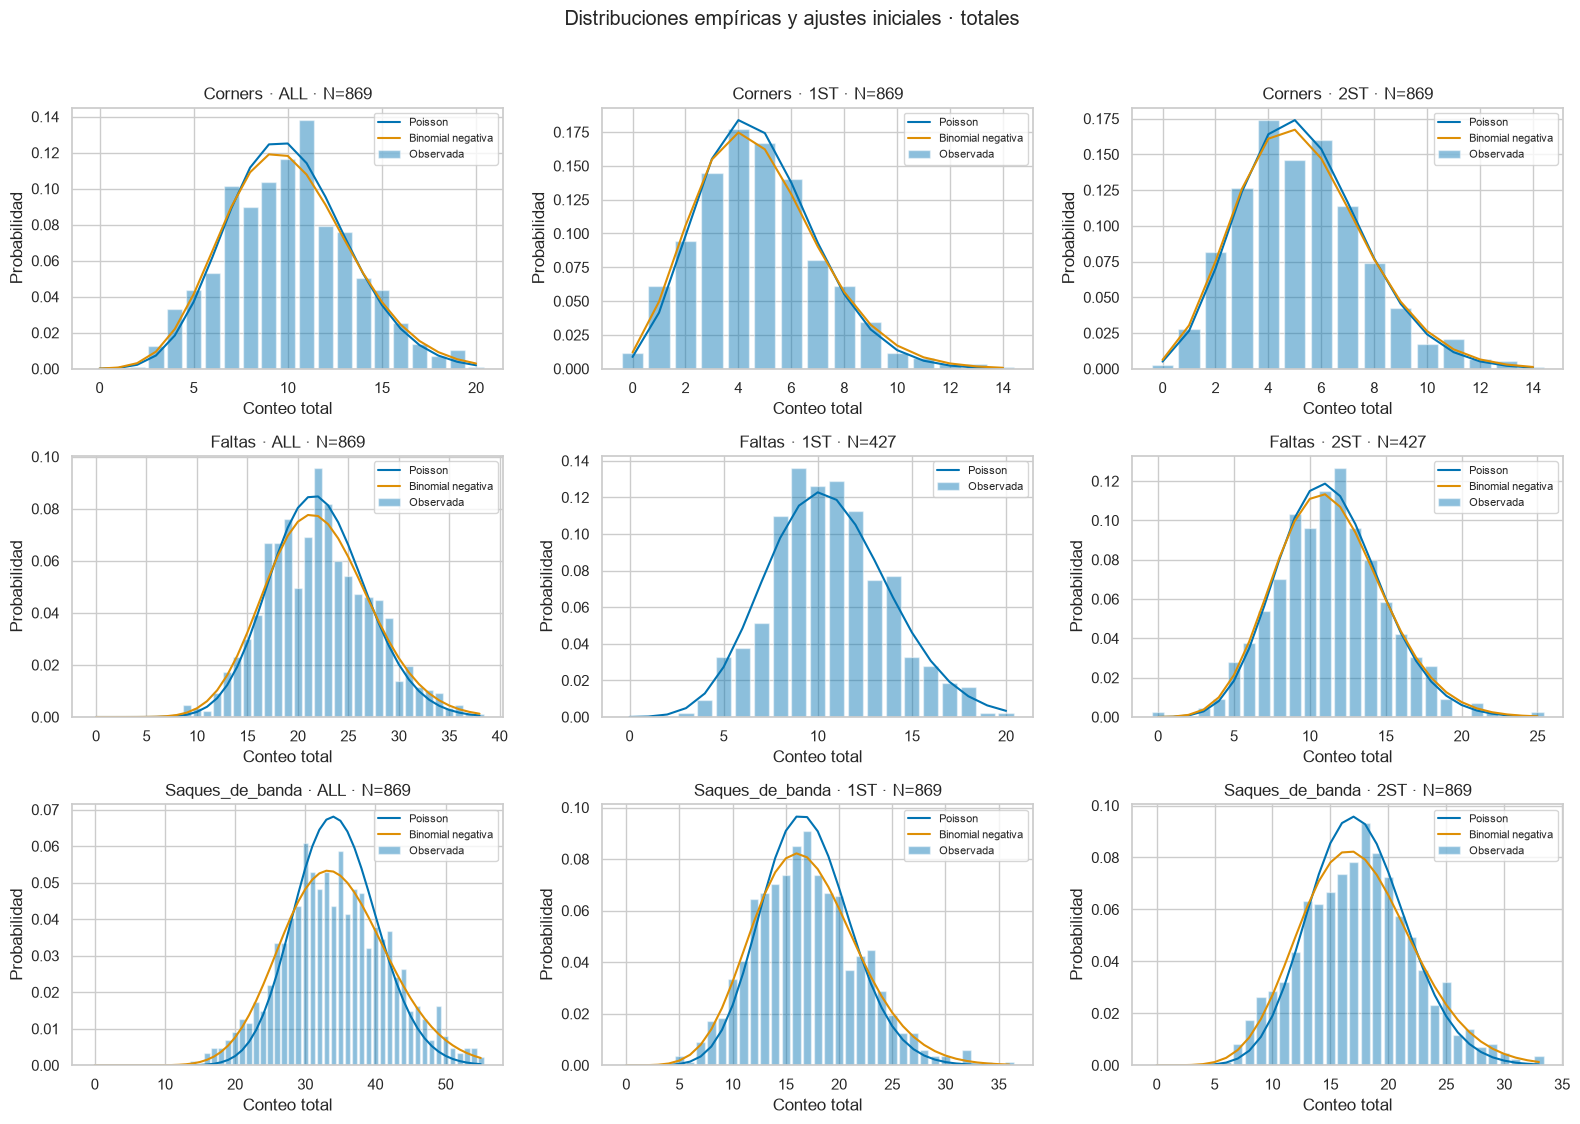

In [9]:
def graficar_distribuciones(datos, mercados=MERCADOS[:3]):
    """Compara masa empírica y PMF; ampliable a otras familias discretas."""
    fig, ejes = plt.subplots(len(mercados), len(PERIODOS), figsize=(16, 11), squeeze=False)
    for i, mercado in enumerate(mercados):
        for j, periodo in enumerate(PERIODOS):
            ax = ejes[i, j]
            x = datos.loc[datos.Periodo.eq(periodo), mercado].dropna()
            ajuste = ajustar_conteos(x)
            ax.set_title(f"{mercado} · {periodo} · N={len(x)}")
            if x.empty:
                ax.text(.5, .5, "Sin datos", ha="center", transform=ax.transAxes)
                continue
            soporte = np.arange(0, int(x.max()) + 1)
            empirica = x.value_counts(normalize=True).reindex(soporte, fill_value=0)
            ax.bar(soporte, empirica, alpha=.45, label="Observada")
            ax.plot(soporte, stats.poisson.pmf(soporte, ajuste["Media"]), label="Poisson")
            if np.isfinite(ajuste["NB_r"]):
                ax.plot(soporte, stats.nbinom.pmf(soporte, ajuste["NB_r"], ajuste["NB_p"]),
                        label="Binomial negativa")
            ax.set(xlabel="Conteo total", ylabel="Probabilidad")
            ax.legend(fontsize=8)
    fig.suptitle("Distribuciones empíricas y ajustes iniciales · totales", y=1.02)
    fig.tight_layout()
    return fig

fig_distribuciones = graficar_distribuciones(df_partido_total)
plt.show()
plt.close(fig_distribuciones)

## Sección 6 · Visualizaciones y Correlación de Features Candidatas

Histogramas discretos y KDE como guía visual (la KDE no es una PMF); boxplots por
condición; evolución por ronda separada por edición con N por ronda; correlaciones
Spearman y sus tamaños muestrales pareados. Las rondas son ordinales, pueden tener
reprogramaciones y no sustituyen `Fecha_hora_utc` para validación temporal.

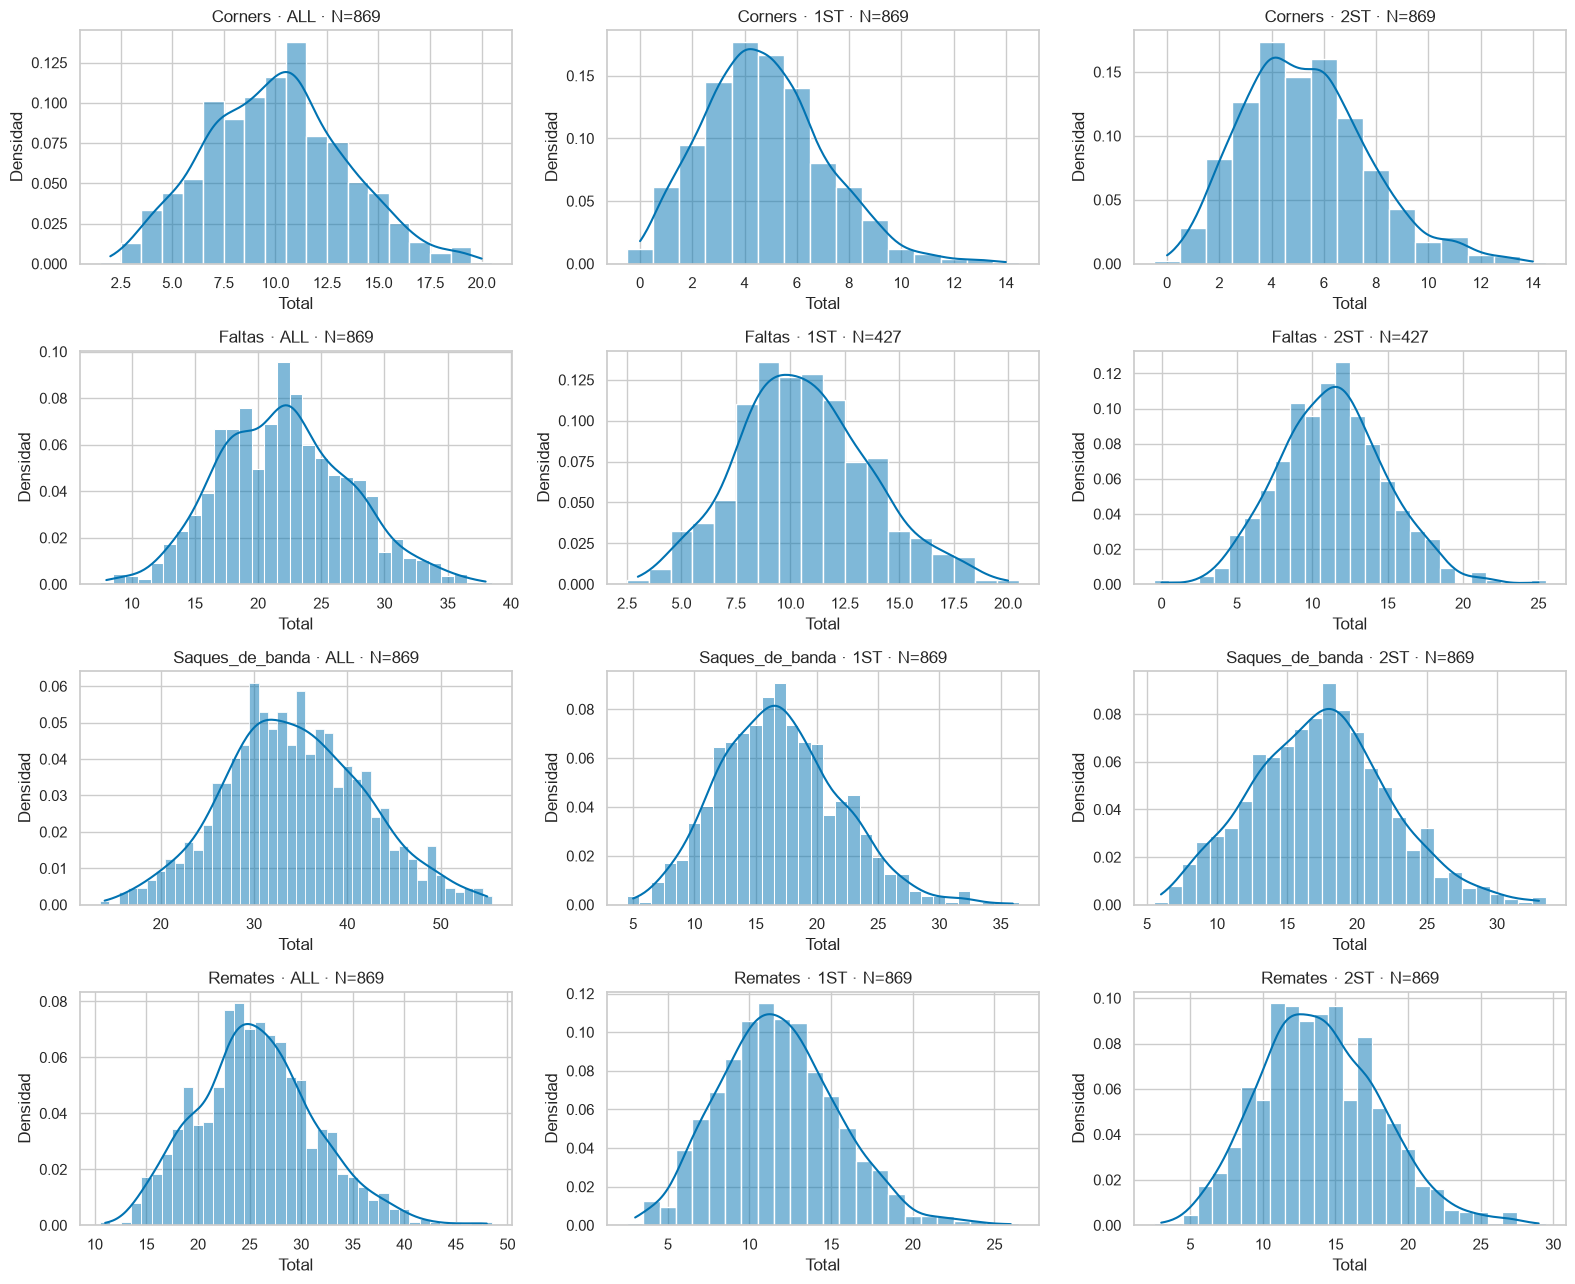

In [10]:
fig, ejes = plt.subplots(len(MERCADOS), len(PERIODOS), figsize=(16, 13))
for i, mercado in enumerate(MERCADOS):
    for j, periodo in enumerate(PERIODOS):
        ax = ejes[i, j]
        x = df_partido_total.loc[df_partido_total.Periodo.eq(periodo), mercado].dropna()
        if len(x):
            sns.histplot(x=x, discrete=True, stat="density", ax=ax,
                         kde=len(x) >= 3 and x.nunique() > 1,
                         kde_kws={"cut": 0, "clip": (0, None)})
        else:
            ax.text(.5, .5, "Sin datos", ha="center", transform=ax.transAxes)
        ax.set(title=f"{mercado} · {periodo} · N={len(x)}", xlabel="Total", ylabel="Densidad")
fig.tight_layout()
plt.show()
plt.close(fig)

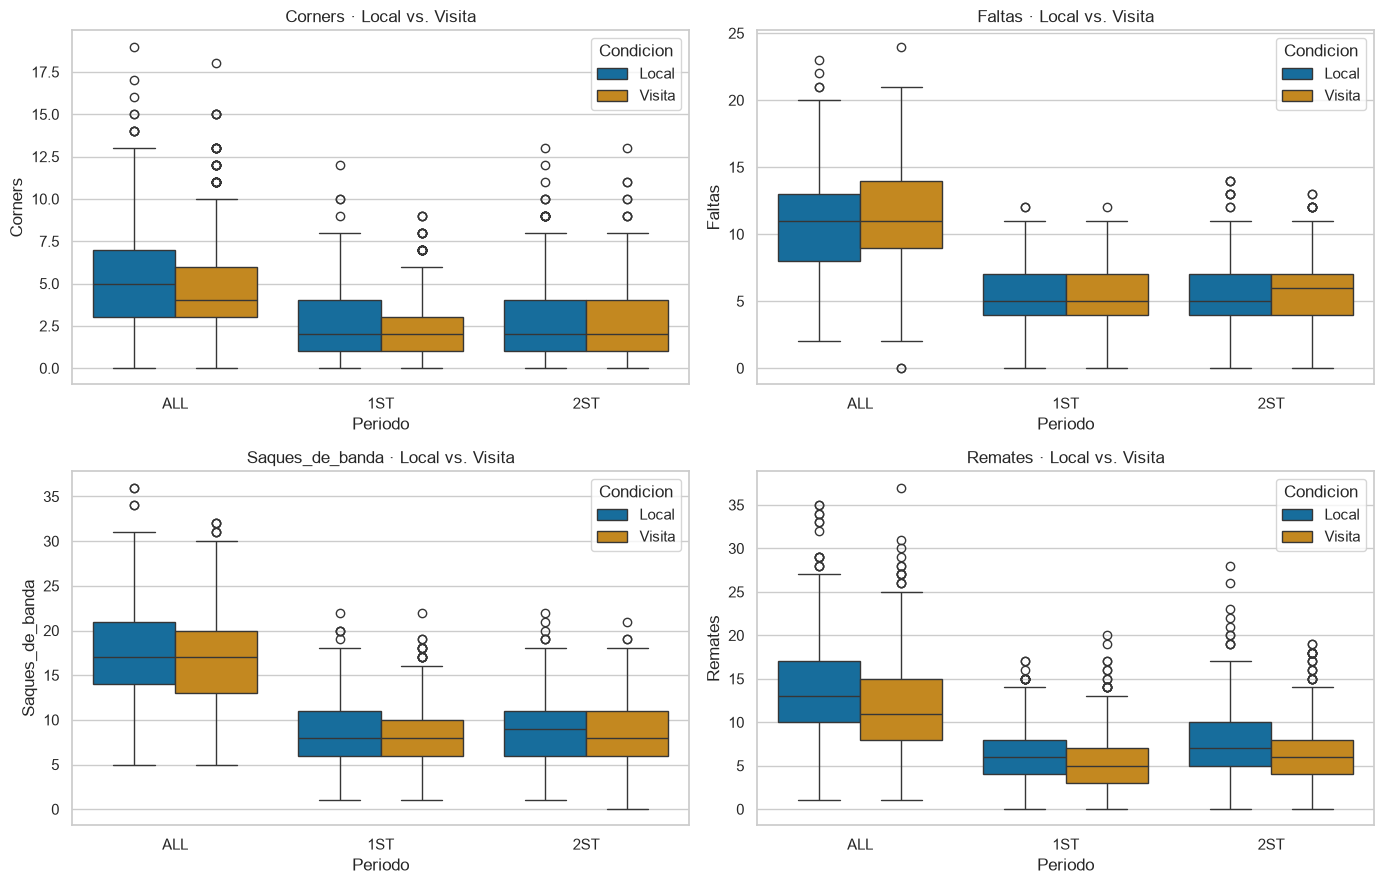

In [11]:
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))
for mercado, ax in zip(MERCADOS, ejes.flat):
    if df_equipo[mercado].notna().any():
        sns.boxplot(data=df_equipo, x="Periodo", y=mercado, hue="Condicion",
                    order=PERIODOS, hue_order=["Local", "Visita"], ax=ax)
    ax.set_title(f"{mercado} · Local vs. Visita")
fig.tight_layout()
plt.show()
plt.close(fig)

,Nombre_liga,Temporada,Ronda_num,Mercado,N,Media
0,Premier League,24/25,1,Corners,10,10.700
1,Premier League,24/25,1,Faltas,10,24.600
2,Premier League,24/25,1,Remates,10,23.900
3,Premier League,24/25,1,Saques_de_banda,10,34.600
4,Premier League,24/25,2,Corners,10,11.300
...,...,...,...,...,...,...
343,Premier League,26/27,10,Saques_de_banda,10,36.300
344,Premier League,26/27,11,Corners,9,10.889
345,Premier League,26/27,11,Faltas,9,26.333
346,Premier League,26/27,11,Remates,9,28.889


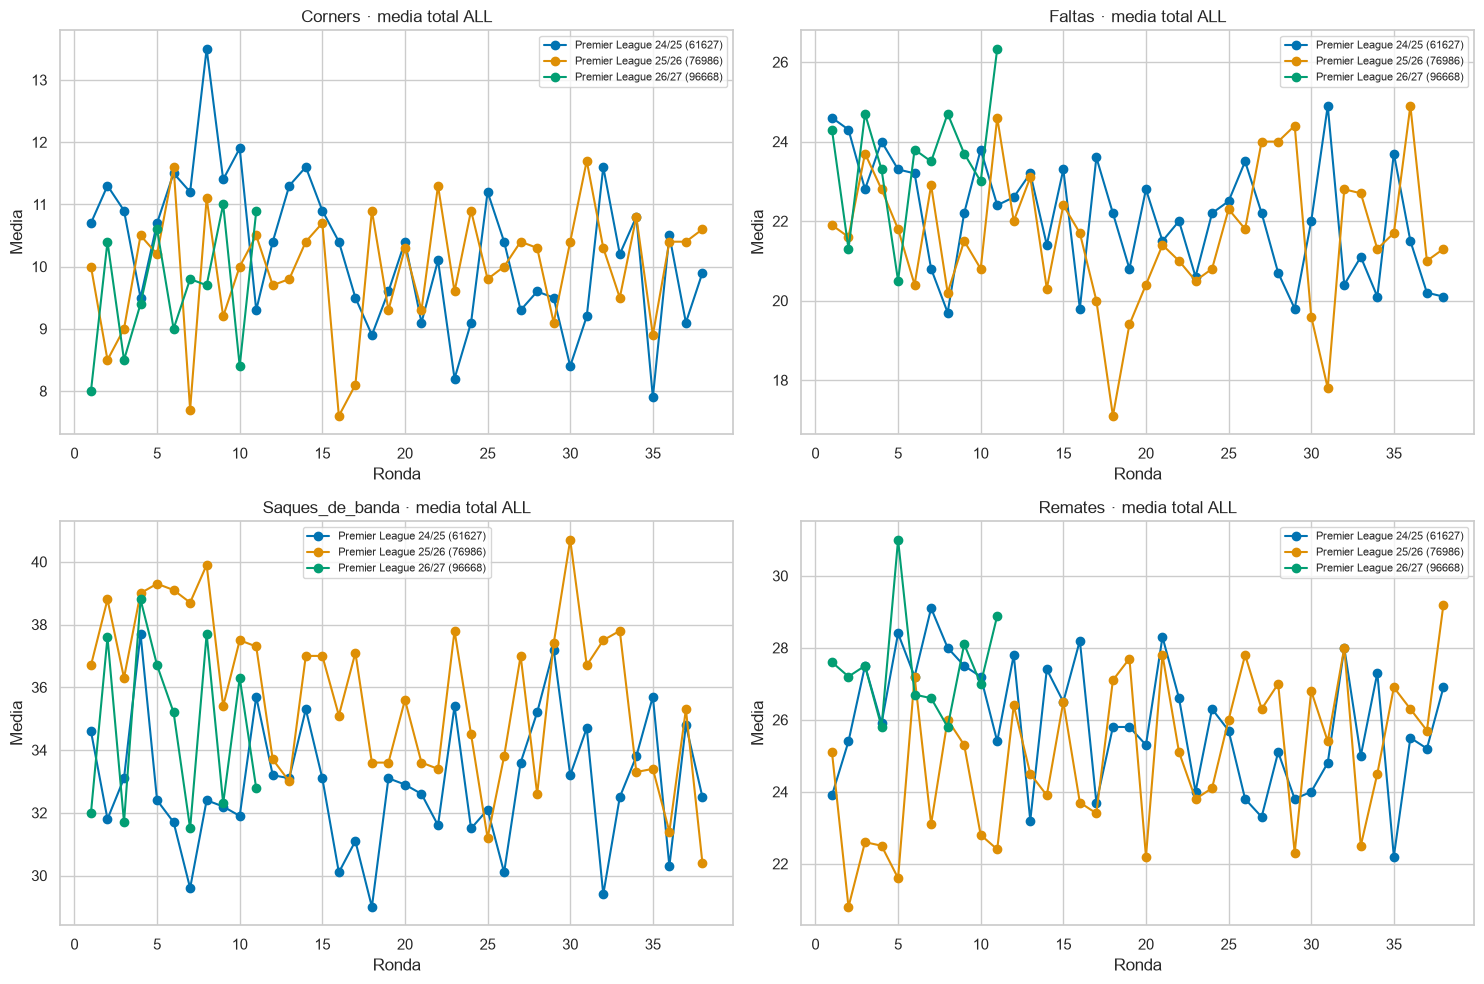

In [12]:
# Media y N por ronda, sin juntar temporadas ni inventar jornadas ausentes.
evolucion = df_partido_total.loc[df_partido_total.Periodo.eq(PERIODO_GRAFICO)].copy()
evolucion["Ronda_num"] = pd.to_numeric(evolucion.Ronda, errors="coerce")
evolucion = evolucion.loc[evolucion.Ronda_num.notna()]
resumen_rondas = describir(evolucion, ["Id_liga", "Nombre_liga", "Temporada", "Ronda_num"])
display(resumen_rondas[["Nombre_liga", "Temporada", "Ronda_num", "Mercado", "N", "Media"]])
fig, ejes = plt.subplots(2, 2, figsize=(15, 10))
for mercado, ax in zip(MERCADOS, ejes.flat):
    for (liga, nombre, temporada), bloque in resumen_rondas.loc[
        resumen_rondas.Mercado.eq(mercado)
    ].groupby(["Id_liga", "Nombre_liga", "Temporada"]):
        bloque = bloque.sort_values("Ronda_num")
        ax.plot(bloque.Ronda_num, bloque.Media, marker="o", label=f"{nombre} {temporada} ({liga})")
    ax.set(title=f"{mercado} · media total {PERIODO_GRAFICO}", xlabel="Ronda", ylabel="Media")
    if ax.lines:
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

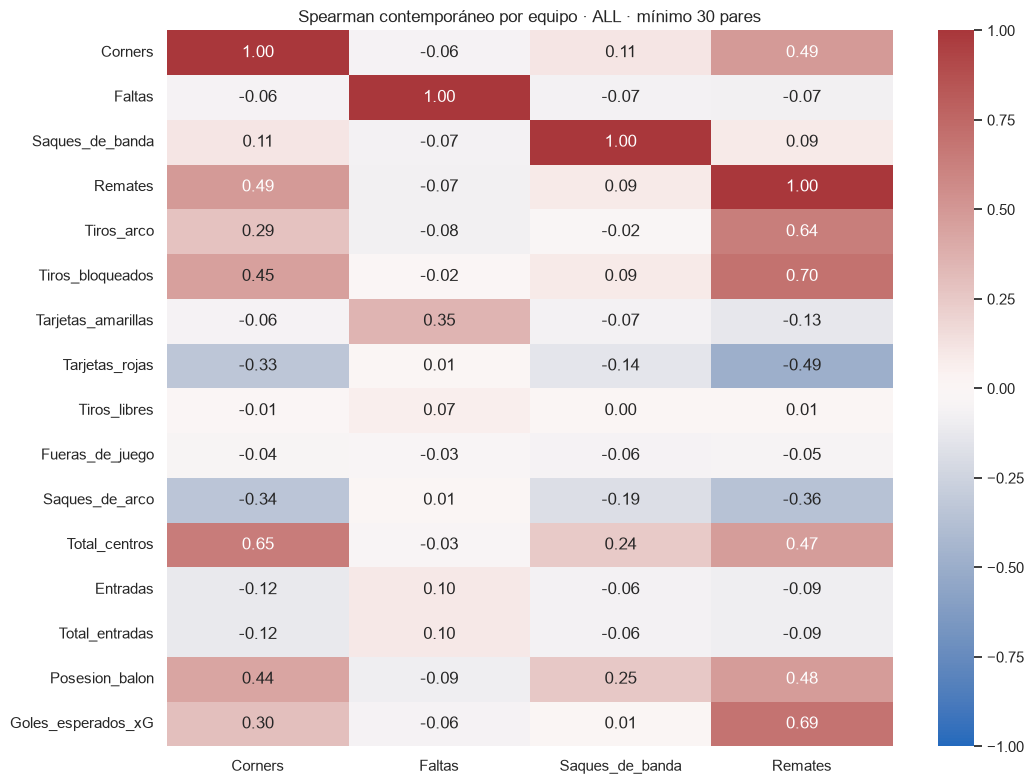

**N pareado · ALL**

,Corners,Faltas,Saques_de_banda,Remates
Corners,1738,1738,1738,1738
Faltas,1738,1738,1738,1738
Saques_de_banda,1738,1738,1738,1738
Remates,1738,1738,1738,1738
Tiros_arco,1738,1738,1738,1738
Tiros_bloqueados,1734,1734,1734,1734
Tarjetas_amarillas,1672,1672,1672,1672
Tarjetas_rojas,212,212,212,212
Tiros_libres,1738,1738,1738,1738
Fueras_de_juego,1648,1648,1648,1648


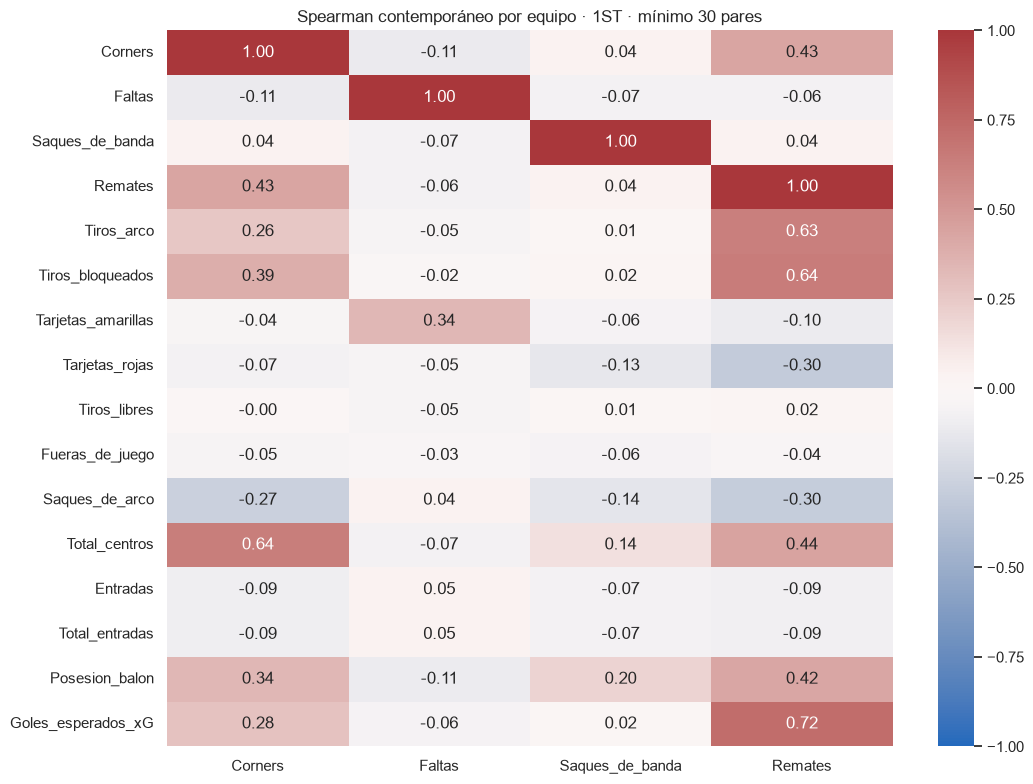

**N pareado · 1ST**

,Corners,Faltas,Saques_de_banda,Remates
Corners,1738,854,1738,1738
Faltas,854,854,854,854
Saques_de_banda,1738,854,1738,1738
Remates,1738,854,1738,1738
Tiros_arco,1738,854,1738,1738
Tiros_bloqueados,1734,852,1734,1734
Tarjetas_amarillas,1672,828,1672,1672
Tarjetas_rojas,212,104,212,212
Tiros_libres,1738,854,1738,1738
Fueras_de_juego,1648,818,1648,1648


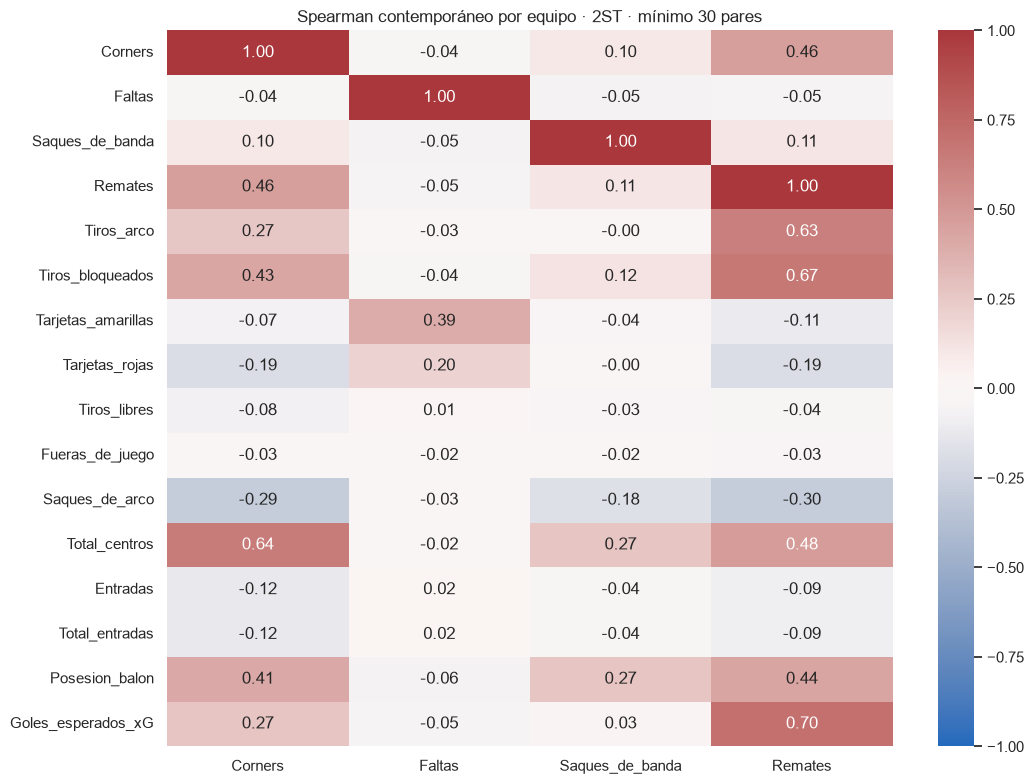

**N pareado · 2ST**

,Corners,Faltas,Saques_de_banda,Remates
Corners,1738,854,1738,1738
Faltas,854,854,854,854
Saques_de_banda,1738,854,1738,1738
Remates,1738,854,1738,1738
Tiros_arco,1738,854,1738,1738
Tiros_bloqueados,1734,852,1734,1734
Tarjetas_amarillas,1672,828,1672,1672
Tarjetas_rojas,212,104,212,212
Tiros_libres,1738,854,1738,1738
Fueras_de_juego,1648,818,1648,1648


In [13]:
correlaciones_por_periodo = {}
for periodo in PERIODOS:
    corr, n_pares = correlaciones(df_equipo, periodo, MIN_N_CORRELACION)
    correlaciones_por_periodo[periodo] = {"spearman": corr, "n_pares": n_pares}
    fig, ax = plt.subplots(figsize=(11, 8))
    matriz = corr.loc[list(METRICAS), list(MERCADOS)]
    if matriz.notna().any().any():
        sns.heatmap(matriz, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True,
                    fmt=".2f", mask=matriz.isna(), ax=ax)
    else:
        ax.text(.5, .5, "Sin pares suficientes o variables constantes", ha="center", transform=ax.transAxes)
    ax.set_title(f"Spearman contemporáneo por equipo · {periodo} · mínimo {MIN_N_CORRELACION} pares")
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    display(Markdown(f"**N pareado · {periodo}**"), n_pares.loc[list(METRICAS), list(MERCADOS)])

### Puente a Fase 2 y líneas exploratorias

La tabla final propone una rejilla de líneas alrededor de la mediana histórica,
en pasos de 0,5 (sin devolución/push). Son **hipótesis de investigación**, no líneas
disponibles ni recomendaciones. Las frecuencias over son retrospectivas: no son
probabilidades calibradas ni evidencia de EV. Para Fase 2, seleccionar líneas
exclusivamente en entrenamiento y contrastar cuotas pre-partido con timestamp.

No usar posesión, xG, remates ni ninguna estadística del partido a predecir. Crear
ventanas históricas por equipo y rival con orden UTC y `shift(1)`; excluir encuentros
simultáneos y exigir que los resultados estuvieran disponibles antes del corte.
El esquema actual no contiene hora de disponibilidad de estadísticas ni cuotas.
Consultar `docs/estrategia-mercados-volumen.md` para criterios y limitaciones.

In [14]:
lineas_exploratorias = []
for periodo in PERIODOS:
    for mercado in MERCADOS[:3]:
        x = df_partido_total.loc[df_partido_total.Periodo.eq(periodo), mercado].dropna()
        if x.empty:
            continue
        centro = np.floor(x.median()) + .5
        for linea in sorted({max(.5, centro - 1), centro, centro + 1}):
            lineas_exploratorias.append({
                "Periodo": periodo, "Mercado": mercado, "N": len(x),
                "Linea": linea, "Over_historico_pct": 100 * x.gt(linea).mean(),
            })
lineas_exploratorias = pd.DataFrame(lineas_exploratorias)
display(lineas_exploratorias)
display(Markdown("**Ejecución completada.** Los DataFrames quedan en memoria para ampliar "
                 "el análisis; no se escribió en SQLite. Revisar cobertura, estratos y "
                 "validación temporal antes de elegir mercados."))

,Periodo,Mercado,N,Linea,Over_historico_pct
0,ALL,Corners,869,9.500,56.157
1,ALL,Corners,869,10.500,44.534
2,ALL,Corners,869,11.500,30.725
3,ALL,Faltas,869,21.500,54.200
4,ALL,Faltas,869,22.500,44.649
5,ALL,Faltas,869,23.500,36.479
6,ALL,Saques_de_banda,869,33.500,52.589
7,ALL,Saques_de_banda,869,34.500,48.216
8,ALL,Saques_de_banda,869,35.500,42.348
9,1ST,Corners,869,4.500,51.093


**Ejecución completada.** Los DataFrames quedan en memoria para ampliar el análisis; no se escribió en SQLite. Revisar cobertura, estratos y validación temporal antes de elegir mercados.